# 3.0 — Análisis de patrones de uso y ubicación de estaciones MiBici (P3)
**Equipo 15 · MiBici 2024 · Exploración previa al baseline de clustering**

**Pregunta P3:** ¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?

**Objetivos:** comprobar cobertura y coordenadas, construir perfiles estadísticos por estación, explorar agrupaciones K-Means, comparar métricas internas y visualizar grupos sobre el plano geográfico. Esta es una **exploración**, no el pipeline definitivo de MLflow.

**Principios:** no utilizar identificadores personales; no modificar CSV originales; no incluir latitud/longitud en las variables de clustering iniciales. El catálogo `nomenclatura_2026_09.csv` es posterior al periodo de viajes (2024), por lo que sus ubicaciones describen la referencia geográfica disponible, **no necesariamente una configuración histórica idéntica**.

## 0. Entorno y archivos
Ejecutar desde VS Code con el kernel `mlops`, con el notebook dentro de `notebooks/`. Las rutas se detectan desde la raíz del repositorio o desde `notebooks/`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").is_dir():
    ROOT = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    ROOT = cwd.parent
else:
    raise FileNotFoundError(f"No se encontró data/raw desde {cwd}")
RAW = ROOT / "data" / "raw"
CSV_FILES = sorted(RAW.glob("datos_abiertos_2024_*.csv"))
CATALOGO_FILE = RAW / "nomenclatura_2026_09.csv"
CHUNK_SIZE = 100_000
SEED = 42
assert len(CSV_FILES) == 12, f"Se esperaban 12 CSV: {len(CSV_FILES)}"
assert CATALOGO_FILE.exists(), f"No existe {CATALOGO_FILE}"
print("Raíz:", ROOT)
print("Archivos de viajes:", len(CSV_FILES))
print("Catálogo:", CATALOGO_FILE.name)
print("pandas:", pd.__version__)


Raíz: /Users/josemtzromero01/Documents/Maestria-MNA/MLOps/week5/TC5061-Proyecto-Equipo15
Archivos de viajes: 12
Catálogo: nomenclatura_2026_09.csv
pandas: 3.0.6


## 1. Nomenclatura, coordenadas y capacidades
Inspeccionamos el catálogo antes de utilizarlo. La ubicación se usa **solo para representar los clusters sobre un mapa**, no para construirlos.

In [2]:
catalogo = pd.read_csv(CATALOGO_FILE, dtype=str, encoding="utf-8-sig")
catalogo.columns = catalogo.columns.str.strip()
print("Forma:", catalogo.shape)
print("Columnas:", catalogo.columns.tolist())
display(catalogo.head())
display(pd.DataFrame({"faltantes": catalogo.isna().sum(),
                      "porcentaje": (100 * catalogo.isna().mean()).round(2)}))
required = {"id", "latitude", "longitude", "dpcapacity"}
assert required.issubset(catalogo.columns), f"Faltan columnas: {required-set(catalogo.columns)}"
estaciones = catalogo[["id", "name", "latitude", "longitude", "dpcapacity"]].copy()
estaciones.columns = ["estacion", "nombre", "latitud", "longitud", "capacidad"]
estaciones["estacion"] = estaciones["estacion"].str.strip()
for c in ["latitud", "longitud", "capacidad"]:
    estaciones[c] = pd.to_numeric(estaciones[c], errors="coerce")
print("IDs duplicados:", int(estaciones["estacion"].duplicated().sum()))
print("Coordenadas faltantes:", int(estaciones[["latitud","longitud"]].isna().any(axis=1).sum()))
print("Capacidades <= 0:", int((estaciones["capacidad"] <= 0).sum()))
display(estaciones[["latitud", "longitud", "capacidad"]].describe().T)


Forma: (484, 5)
Columnas: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.34882,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.66769,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691846603895982,-103.3625486588955,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.6811575,-103.339363,11


,faltantes,porcentaje
id,0,0.0
name,0,0.0
latitude,0,0.0
longitude,0,0.0
dpcapacity,0,0.0


IDs duplicados: 0
Coordenadas faltantes: 0
Capacidades <= 0: 4


,count,mean,std,min,25%,50%,75%,max
latitud,484.0,20.678520,0.022032,20.636130,20.665077,20.674390,20.688609,20.739523
longitud,484.0,-103.361871,0.031626,-103.433215,-103.384164,-103.362443,-103.339320,-103.297112
capacidad,484.0,16.882231,4.126942,0.000000,15.000000,15.000000,19.000000,39.000000


## 2. Lectura reproducible y agregación de salidas

Procesaremos los 12 CSV en bloques, conservando solo **estación origen y fecha de inicio**, suficientes para construir perfiles de demanda. Las fechas tienen dos formatos conocidos en 2024; los archivos de septiembre y octubre utilizan día/mes/año y el resto año-mes-día. Julio se lee en UTF-8; los demás en latin1. **La posición de las 8 columnas sigue la estructura validada en el EDA y P2.**

La salida por estación y hora del día se agrupa separando **días laborables (lunes–viernes) y fin de semana (sábado–domingo)**. Además, se calculan totales y días con viajes. Este análisis **no deduplica registros nuevamente**: utiliza el control de duplicados ya efectuado en el EDA.


In [3]:
resumenes = []
meses = []
for f in CSV_FILES:
    mes = int(f.stem[-2:])
    encoding = "utf-8" if mes == 7 else "latin1"
    n = invalidas = ids_vacios = 0
    for chunk in pd.read_csv(f, dtype=str, chunksize=CHUNK_SIZE, encoding=encoding):
        if chunk.shape[1] != 8:
            raise ValueError(f"{f.name}: se esperaban 8 columnas, se leyeron {chunk.shape[1]}")
        chunk.columns = ["viaje_id", "usuario_id", "genero", "anio_nacimiento", "inicio", "fin", "origen", "destino"]
        dates = pd.to_datetime(chunk["inicio"],
            format="%d/%m/%Y %H:%M" if mes in (9,10) else "%Y-%m-%d %H:%M:%S",
            errors="coerce")
        ids = chunk["origen"].astype("string").str.strip()
        n += len(chunk)
        invalidas += int(dates.isna().sum())
        ids_vacios += int(ids.isna().sum() + ids.eq("").fillna(False).sum())
        df = pd.DataFrame({"estacion": ids,
                           "fecha": dates.dt.normalize(),
                           "hora": dates.dt.hour,
                           "fin_de_semana": dates.dt.dayofweek.ge(5)})
        df = df.dropna(subset=["estacion", "fecha", "hora", "fin_de_semana"])
        df = df[df["estacion"].ne("")]
        agrupado = df.groupby(["estacion", "fecha", "hora", "fin_de_semana"], observed=True).size().rename("salidas")
        resumenes.append(agrupado.reset_index())
    meses.append({"mes": mes, "viajes": n, "fechas_invalidas": invalidas,
                  "origen_vacio": ids_vacios})
    print(f"{f.name}: {n:,} viajes")
display(pd.DataFrame(meses))
print("Total viajes:", f"{sum(x['viajes'] for x in meses):,}")


datos_abiertos_2024_01.csv: 391,591 viajes
datos_abiertos_2024_02.csv: 383,732 viajes
datos_abiertos_2024_03.csv: 390,513 viajes
datos_abiertos_2024_04.csv: 405,308 viajes
datos_abiertos_2024_05.csv: 410,806 viajes
datos_abiertos_2024_06.csv: 365,000 viajes
datos_abiertos_2024_07.csv: 364,177 viajes
datos_abiertos_2024_08.csv: 394,894 viajes
datos_abiertos_2024_09.csv: 390,072 viajes
datos_abiertos_2024_10.csv: 418,690 viajes
datos_abiertos_2024_11.csv: 391,089 viajes
datos_abiertos_2024_12.csv: 340,049 viajes


,mes,viajes,fechas_invalidas,origen_vacio
0,1,391591,0,0
1,2,383732,0,0
2,3,390513,0,0
3,4,405308,0,0
4,5,410806,0,0
5,6,365000,0,0
6,7,364177,0,0
7,8,394894,0,0
8,9,390072,0,0
9,10,418690,0,0


Total viajes: 4,645,921


## 3. Panel de perfiles por estación
La intensidad absoluta y la forma del perfil se estudian por separado. Los porcentajes de actividad por franja horaria sirven para reconocer patrones, mientras que el volumen permite interpretar el tamaño de operación.

In [4]:
salidas_agg = pd.concat(resumenes, ignore_index=True)
salidas_agg = (salidas_agg.groupby(["estacion","fecha","hora","fin_de_semana"], as_index=False)
               ["salidas"].sum())
assert salidas_agg["salidas"].sum() == sum(x["viajes"] - x["fechas_invalidas"] - x["origen_vacio"] for x in meses), "Revisar discrepancia de eventos"
print("Estaciones con salidas:", salidas_agg["estacion"].nunique())
print("Filas agregadas estación-fecha-hora:", len(salidas_agg))

# Conteo por estación × tipo de día × hora (48 campos para un perfil)
por_hora = (salidas_agg.groupby(["estacion","fin_de_semana","hora"], observed=True)["salidas"]
            .sum().unstack(["fin_de_semana", "hora"], fill_value=0))
columnas_hora = pd.MultiIndex.from_product([[False, True], range(24)], names=["fin_de_semana","hora"])
por_hora = por_hora.reindex(columns=columnas_hora, fill_value=0)
por_hora.columns = [f"{'fs' if fs else 'lv'}_{hora:02d}" for fs, hora in por_hora.columns]
volumen = salidas_agg.groupby("estacion")["salidas"].sum().rename("salidas_2024")
activos = salidas_agg.groupby("estacion")["fecha"].nunique().rename("dias_con_salidas")
perfiles = por_hora.join(volumen).join(activos)
perfiles["media_diaria_calendario"] = perfiles["salidas_2024"] / 366
perfiles["fraccion_fin_semana"] = perfiles[[f"fs_{h:02d}" for h in range(24)]].sum(axis=1) / perfiles["salidas_2024"]
perfiles["fraccion_manana_laboral"] = perfiles[[f"lv_{h:02d}" for h in range(6,12)]].sum(axis=1) / perfiles["salidas_2024"]
perfiles["fraccion_tarde_laboral"] = perfiles[[f"lv_{h:02d}" for h in range(16,21)]].sum(axis=1) / perfiles["salidas_2024"]
print("Estaciones:", len(perfiles))
display(perfiles[["salidas_2024", "dias_con_salidas", "media_diaria_calendario",
                 "fraccion_fin_semana", "fraccion_manana_laboral", "fraccion_tarde_laboral"]].describe().T)


Estaciones con salidas: 370
Filas agregadas estación-fecha-hora: 1519050
Estaciones: 370


,count,mean,std,min,25%,50%,75%,max
salidas_2024,370.0,12556.543243,11748.693310,26.000000,4598.000000,9011.000000,17450.250000,96419.000000
dias_con_salidas,370.0,355.108108,54.526483,14.000000,365.000000,366.000000,366.000000,366.000000
media_diaria_calendario,370.0,34.307495,32.100255,0.071038,12.562842,24.620219,47.678279,263.439891
fraccion_fin_semana,370.0,0.203467,0.046401,0.081292,0.177727,0.200421,0.224217,0.417463
fraccion_manana_laboral,370.0,0.260059,0.082123,0.038462,0.196158,0.257207,0.323705,0.520475
fraccion_tarde_laboral,370.0,0.300436,0.079025,0.152715,0.243909,0.288820,0.350794,0.615385


## 4. Cobertura espacial y estaciones de baja actividad
Antes de calcular distancias entre perfiles, verificamos que existan coordenadas y detectamos estaciones con muy pocos viajes. Una estación casi inactiva puede tener proporciones horarias inestables.

Con coordenadas completas: 370 de 370
Sin catálogo: 0
Estaciones con menos de 100 salidas: 2
Estaciones con menos de 1000 salidas: 11


,salidas_2024,dias_con_salidas,nombre,latitud,longitud
estacion,,,,,
391,26,14,(ZPN-078) Lago Constanza / San Jorge,20.714856,-103.375117
398,69,14,(GDL-281) Nevado Toluca / Av de los Maestros,20.695075,-103.333456
397,100,14,(GDL-279) Belen / Av. de los Maestros,20.693053,-103.345900
394,127,15,(ZPN-077) Helios / Av. Tepeyac,20.655775,-103.421877
393,146,16,(GDL-277) Av. 8 de julio / Alemania,20.662729,-103.354767
395,154,15,(GDL-276) Francisco de Quevedo / Miguel Lerdo,20.671045,-103.381349
392,161,16,(GDL-278) Ignacio Ramirez / Del Istmo,20.694721,-103.363398
396,297,15,(GDL-280) Av. Vallarta / C. Aurelio Aceves,20.674248,-103.388504
104,515,138,(ZPN-104) Av. D / C. 9,20.718288,-103.371795


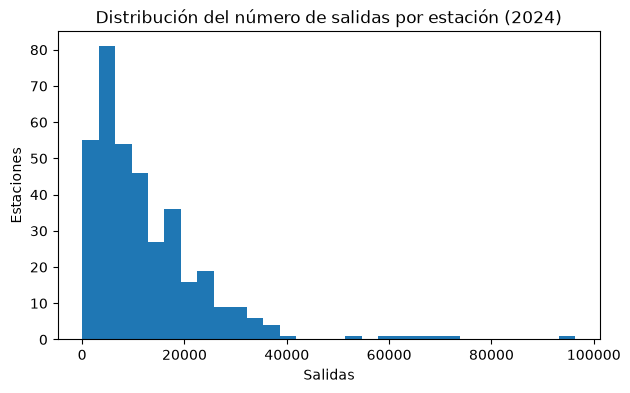

In [5]:
cobertura = perfiles.join(estaciones.set_index("estacion"), how="left")
print("Con coordenadas completas:", cobertura[["latitud","longitud"]].notna().all(axis=1).sum(), "de", len(cobertura))
print("Sin catálogo:", cobertura["nombre"].isna().sum())
print("Estaciones con menos de 100 salidas:", int((cobertura["salidas_2024"] < 100).sum()))
print("Estaciones con menos de 1000 salidas:", int((cobertura["salidas_2024"] < 1000).sum()))
display(cobertura.nsmallest(12, "salidas_2024")[["salidas_2024","dias_con_salidas","nombre","latitud","longitud"]])
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(cobertura["salidas_2024"], bins=30)
ax.set(title="Distribución del número de salidas por estación (2024)", xlabel="Salidas", ylabel="Estaciones")
plt.show()


## 5. Variables para el clustering y normalización

**Criterio inicial:** estaciones con al menos **100 viajes de salida** durante 2024, capacidad de formar un perfil y coordenadas conocidas para la visualización. Este umbral es **exploratorio y configurable**, no una regla definitiva; registraremos cuántas estaciones se excluyen.

Para representar el patrón, calcularemos la distribución porcentual de salidas **dentro de cada tipo de día** (24 fracciones de laborables + 24 de fines de semana). Así la forma del perfil no queda dominada por el mayor número de días laborables. Agregaremos `log1p(media_diaria_calendario)` para distinguir niveles de actividad. La estandarización se ajusta al universo utilizado en esta exploración; en el baseline reproducible hay que conservar los parámetros y controlar el conjunto analizado.

**Importante:** no añadimos `latitud`, `longitud` ni `capacidad` a la matriz de clustering; solo se utilizarán para describir resultados.


In [6]:
MIN_SALIDAS = 100  # Se puede analizar sensibilidad más adelante
incluidas = cobertura.loc[
    (cobertura["salidas_2024"] >= MIN_SALIDAS)
    & cobertura[["latitud","longitud"]].notna().all(axis=1)
].copy()
print("Estaciones incluidas:", len(incluidas))
print("Estaciones excluidas:", len(cobertura)-len(incluidas))

lv_cols = [f"lv_{h:02d}" for h in range(24)]
fs_cols = [f"fs_{h:02d}" for h in range(24)]
features = pd.DataFrame(index=incluidas.index)
for cols, pref in [(lv_cols,"laboral"), (fs_cols,"finde")]:
    totales = incluidas[cols].sum(axis=1).replace(0, np.nan)
    # Si no hay viajes de ese tipo, perfil todo ceros (se deja indicado como limitación).
    for h, columna in enumerate(cols):
        features[f"{pref}_{h:02d}"] = (incluidas[columna] / totales).fillna(0.0)
features["log_media_diaria"] = np.log1p(incluidas["media_diaria_calendario"])
print("Estaciones sin salidas laborales:", int(incluidas[lv_cols].sum(axis=1).eq(0).sum()))
print("Estaciones sin salidas de fin de semana:", int(incluidas[fs_cols].sum(axis=1).eq(0).sum()))
assert np.isfinite(features.to_numpy()).all(), "Se detectaron valores no finitos"
scaler = StandardScaler()
X = scaler.fit_transform(features)
print("Matriz:", X.shape)
display(features.head(3).iloc[:, [0, 8, 18, 24, 32, 42, 48]])


Estaciones incluidas: 368
Estaciones excluidas: 2
Estaciones sin salidas laborales: 0
Estaciones sin salidas de fin de semana: 0
Matriz: (368, 49)


,laboral_00,laboral_08,laboral_18,finde_00,finde_08,finde_18,log_media_diaria
estacion,,,,,,,
10,0.003043,0.122978,0.063456,0.006202,0.035145,0.068517,3.851542
100,0.000328,0.103177,0.040616,0.000000,0.048059,0.018484,2.381366
101,0.000000,0.022065,0.070134,0.008264,0.037190,0.057851,1.634797


## 6. Exploración de K y métricas internas
Comparamos K-Means con `k=2` a `k=8`, `random_state=42`, `n_init=20`. **Silhouette** (más alto suele indicar grupos más separados) y **Davies–Bouldin** (más bajo suele indicar mejor separación) son métricas internas; no prueban que exista una segmentación única o causal.

,k,silhouette,davies_bouldin,inercia,min_estaciones_grupo,max_estaciones_grupo
0,2,0.127636,2.369866,13689.811821,177,191
1,3,0.112191,2.407129,12900.462966,64,157
2,4,0.082353,2.476469,12257.560061,35,141
3,5,0.073328,2.378216,11843.284708,29,128
4,6,0.060343,2.478017,11468.528303,28,105
5,7,0.064895,2.279183,11141.187068,5,88
6,8,0.073785,2.198064,10897.123692,4,89


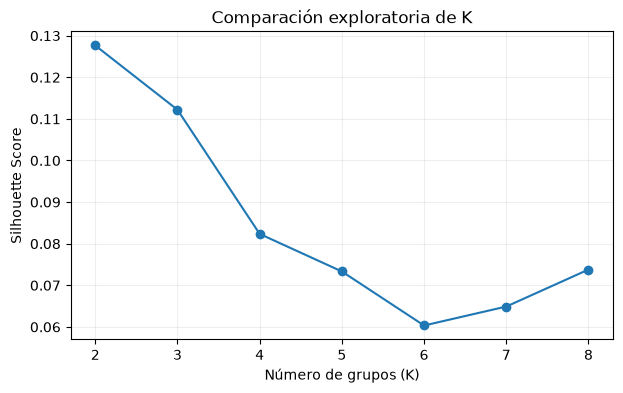

In [7]:
K_VALUES = list(range(2, min(8, len(features)-1)+1))
if not K_VALUES:
    raise ValueError("No hay suficientes estaciones para evaluar clustering")
comparacion = []
modelos = {}
for k in K_VALUES:
    modelo = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = modelo.fit_predict(X)
    modelos[k] = (modelo, labels)
    comparacion.append({"k": k,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "inercia": modelo.inertia_,
        "min_estaciones_grupo": int(pd.Series(labels).value_counts().min()),
        "max_estaciones_grupo": int(pd.Series(labels).value_counts().max())})
resultados_k = pd.DataFrame(comparacion)
display(resultados_k)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(resultados_k["k"], resultados_k["silhouette"], marker="o")
ax.set(xlabel="Número de grupos (K)", ylabel="Silhouette Score", title="Comparación exploratoria de K")
ax.grid(alpha=.2)
plt.show()


## 7. Selección exploratoria e interpretación

Se selecciona inicialmente el K con mejor **Silhouette Score**, sin usar aún Davies–Bouldin como criterio de desempate automático. Un mejor puntaje no garantiza interpretabilidad: analizaremos además tamaños, volumen y perfiles. El valor final de K podrá cambiar al preparar `p3_baseline.py`. Las etiquetas numéricas de K-Means son **arbitrarias**: “grupo 0” no implica menor actividad que “grupo 1”.


In [8]:
K_EXPLORATORIO = int(resultados_k.loc[resultados_k["silhouette"].idxmax(), "k"])
labels = modelos[K_EXPLORATORIO][1]
agrupadas = incluidas.copy()
agrupadas["grupo"] = labels
print("K exploratorio por Silhouette:", K_EXPLORATORIO)
display(agrupadas.groupby("grupo").agg(
    estaciones=("salidas_2024", "size"),
    salidas_mediana=("salidas_2024", "median"),
    media_diaria_mediana=("media_diaria_calendario", "median"),
    fraccion_fin_semana_mediana=("fraccion_fin_semana", "median"),
    fraccion_manana_laboral_mediana=("fraccion_manana_laboral", "median"),
    fraccion_tarde_laboral_mediana=("fraccion_tarde_laboral", "median")
).round(4))


K exploratorio por Silhouette: 2


,estaciones,salidas_mediana,media_diaria_mediana,fraccion_fin_semana_mediana,fraccion_manana_laboral_mediana,fraccion_tarde_laboral_mediana
grupo,,,,,,
0,177,11828.0,32.3169,0.1930,0.2006,0.3422
1,191,7787.0,21.2760,0.2063,0.3194,0.2484


## 8. Perfiles horarios por grupo
La gráfica muestra las fracciones promedio de viajes por hora dentro de cada tipo de día. Cada curva equivale a la media de perfiles individuales; no representa directamente viajes absolutos.

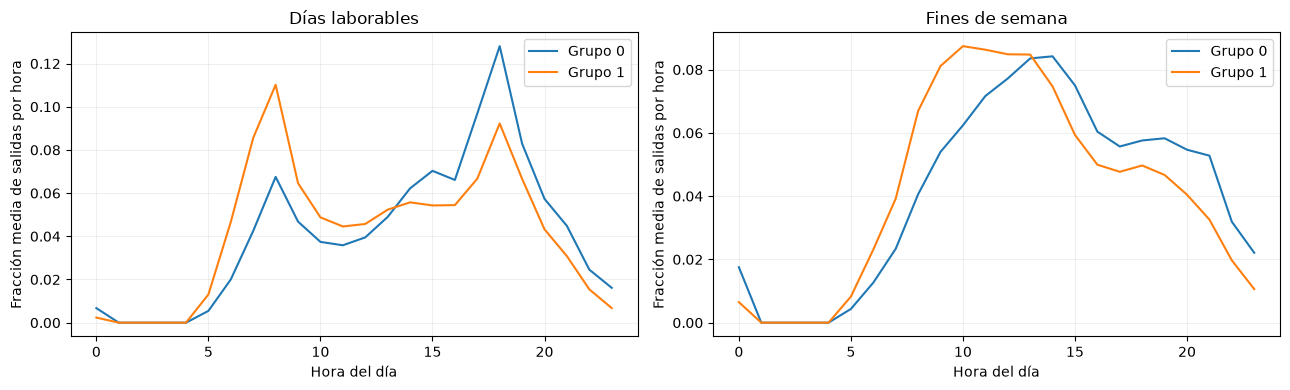

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for grupo in sorted(agrupadas["grupo"].unique()):
    idx = agrupadas.index[agrupadas["grupo"] == grupo]
    h_lv = features.loc[idx, [f"laboral_{h:02d}" for h in range(24)]].mean(axis=0).to_numpy()
    h_fs = features.loc[idx, [f"finde_{h:02d}" for h in range(24)]].mean(axis=0).to_numpy()
    axes[0].plot(range(24), h_lv, label=f"Grupo {grupo}")
    axes[1].plot(range(24), h_fs, label=f"Grupo {grupo}")
for ax, title in zip(axes, ["Días laborables", "Fines de semana"]):
    ax.set(title=title, xlabel="Hora del día", ylabel="Fracción media de salidas por hora")
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 9. Ubicación geográfica de los grupos
Se muestran **puntos de estaciones sobre sus coordenadas**, sin cartografía de fondo. Los colores indican grupos definidos por **uso**, no por ubicación. Revisar si hay agrupación espacial o dispersión, sin inferir causalidad.

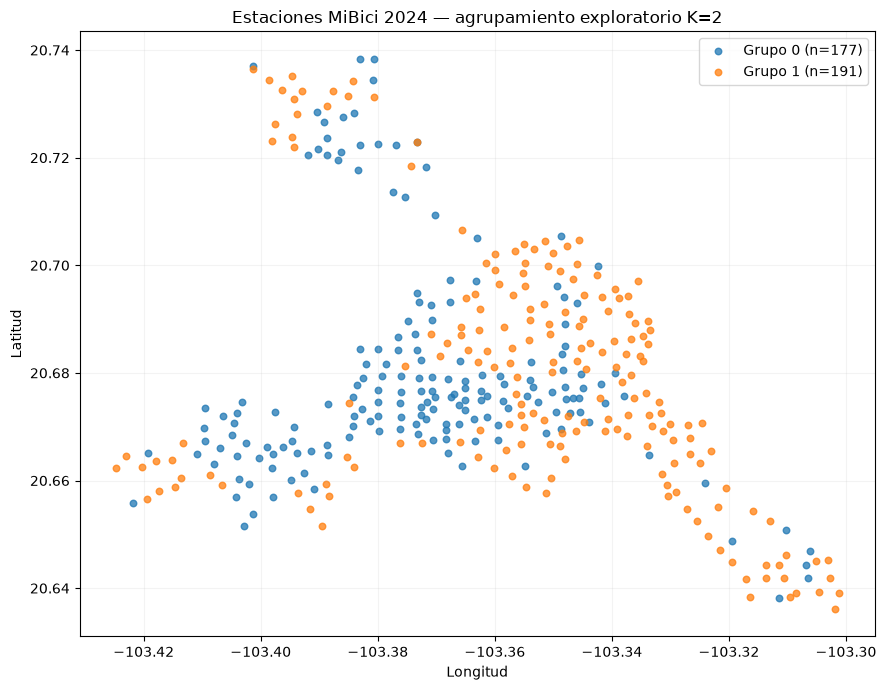

Coordenadas de referencia: nomenclatura_2026_09.csv


In [10]:
fig, ax = plt.subplots(figsize=(9, 7))
for grupo, df in agrupadas.groupby("grupo"):
    ax.scatter(df["longitud"], df["latitud"], s=22, alpha=.75, label=f"Grupo {grupo} (n={len(df)})")
ax.set(title=f"Estaciones MiBici 2024 — agrupamiento exploratorio K={K_EXPLORATORIO}",
       xlabel="Longitud", ylabel="Latitud")
ax.legend()
ax.grid(alpha=.15)
plt.tight_layout()
plt.show()
print("Coordenadas de referencia: nomenclatura_2026_09.csv")


## 10. Conclusiones del análisis exploratorio P3

### 10.1. Calidad y cobertura de los datos

Se procesaron los **12 archivos mensuales de viajes MiBici 2024**, con un total de **4,645,921 viajes**. En el procesamiento de fechas de inicio no se registraron valores inválidos y no se identificaron estaciones de origen vacías. El catálogo de referencia de septiembre de 2026 contiene **484 estaciones**, sin IDs duplicados ni coordenadas faltantes; también se identificaron **4 capacidades iguales a cero**, si bien la capacidad **no se utilizó como característica del clustering**.

Los viajes de 2024 involucran **370 estaciones de origen**, y las **370 cuentan con coordenadas** en el catálogo utilizado. Se identificaron **2 estaciones con menos de 100 salidas**, las cuales se excluyeron del agrupamiento exploratorio. Por tanto, se analizaron **368 estaciones**. Hay **11 estaciones con menos de 1,000 salidas**, incluidas las dos anteriores, por lo que resulta conveniente realizar un análisis de sensibilidad con un umbral de actividad mayor.

### 10.2. Construcción de perfiles de uso

Para cada estación se generaron perfiles de **24 horas en días laborables** y **24 horas en fines de semana**, normalizados según el total de salidas del tipo de día correspondiente. Se agregó la característica de intensidad `log_media_diaria`, obtenida a partir del promedio de salidas diarias sobre los **366 días calendario de 2024**. De este modo, el análisis combina **48 proporciones horarias y 1 indicador de intensidad**, es decir, **49 características por estación**. Antes de aplicar K-Means, las variables se estandarizaron con `StandardScaler`.

Todas las estaciones incluidas contaron con salidas tanto en días laborables como en fines de semana. Es importante reconocer que dividir entre los 366 días de 2024 puede **subestimar la intensidad de las estaciones que tuvieron pocos días con actividad registrada**, ya que no contamos con una serie histórica que confirme su fecha de puesta en operación. En los datos se observaron estaciones con únicamente **14 o 15 días con salidas**.

### 10.3. Comparación de K-Means y selección de grupos

Se probaron soluciones de K-Means para **K = 2 a 8**, utilizando `random_state=42`, `n_init=20` y las mismas 49 características estandarizadas.

| K | Silhouette ↑ | Davies–Bouldin ↓ | Grupo más pequeño |
|---|---:|---:|---:|
| **2** | **0.127636** | 2.369866 | 177 |
| 3 | 0.112191 | 2.407129 | 64 |
| 4 | 0.082353 | 2.476469 | 35 |
| 5 | 0.073328 | 2.378216 | 29 |
| 6 | 0.060343 | 2.478017 | 28 |
| 7 | 0.064895 | 2.279183 | 5 |
| 8 | 0.073785 | **2.198064** | 4 |

Se seleccionó **K = 2 como solución exploratoria**, porque obtuvo el Silhouette Score más alto y generó grupos de tamaños razonablemente equilibrados. Sin embargo, **Silhouette = 0.1276 es bajo**, de modo que **no existe evidencia de grupos fuertemente separados**. El índice Davies–Bouldin fue menor para K = 8, pero esa solución incluyó grupos de apenas 4 estaciones. Por tanto, K = 2 es un **punto de partida interpretable**, no una segmentación definitiva ni necesariamente la mejor para todas las aplicaciones.

### 10.4. Caracterización de los dos grupos

| Característica (mediana) | Grupo 0 | Grupo 1 |
|---|---:|---:|
| Número de estaciones | **177** | **191** |
| Salidas anuales | 11,828 | 7,787 |
| Salidas por día calendario | 32.3169 | 21.2760 |
| Fracción de salidas en fin de semana | 19.30 % | 20.63 % |
| Fracción matutina laboral | 20.06 % | 31.94 % |
| Fracción vespertina laboral | 34.22 % | 24.84 % |

- **Grupo 0: perfil relativamente vespertino.** Reúne 177 estaciones y presenta mayor intensidad mediana de salidas y una proporción más alta de viajes durante la tarde de días laborables.
- **Grupo 1: perfil relativamente matutino.** Reúne 191 estaciones, con menor intensidad mediana y mayor concentración de salidas durante la mañana laboral.

Estas descripciones resumen **tendencias estadísticas del conjunto**, no reglas que cumplan todas las estaciones de cada grupo. La diferencia en la fracción de fin de semana es menor que las diferencias en los periodos matutino y vespertino.

### 10.5. Distribución geográfica

El notebook muestra la ubicación de las estaciones de ambos grupos mediante latitud y longitud del catálogo `nomenclatura_2026_09.csv`. **Las coordenadas no se incorporaron al vector de características**, de manera que el algoritmo agrupó estaciones por patrones de uso, y no por proximidad espacial.

La gráfica permite explorar visualmente la distribución territorial; sin un análisis espacial adicional **no se concluye que exista una concentración geográfica estadísticamente significativa** ni se atribuyen funciones urbanas concretas a los grupos. Las coordenadas de **2026** son referencias para la visualización y **no garantizan la misma ubicación histórica durante 2024**.

### 10.6. Limitaciones y siguientes pasos

1. La separación entre grupos es **débil** según Silhouette; los patrones podrían variar de forma continua, en lugar de formar categorías naturales claramente distinguibles.
2. El resultado depende de las **49 variables**, su estandarización, los criterios de exclusión de estaciones y los parámetros de K-Means. Conviene probar variantes de características más compactas, así como distintos filtros de actividad.
3. El perfil incluye **salidas**, no llegadas ni disponibilidad real de bicicletas. Incorporar otras fuentes requerirá construir y reevaluar las características.
4. La intensidad diaria se calcula sobre el **año calendario completo** y puede afectar a estaciones con cobertura temporal parcial.
5. No existe una etiqueta verdadera para contrastar los clusters: las métricas utilizadas son **internas de aprendizaje no supervisado**.
6. Como siguiente etapa, implementar `mibici/modeling/p3_baseline.py` para ejecutar alternativas de K y registrar en **MLflow (`mibici-equipo15`)** los parámetros, métricas internas, manifiesto de archivos y artefactos (gráficas de perfiles y ubicación). Documentar los resultados en `references/P3_INSTRUCCIONES.md`.

**Conclusión general:** los viajes de MiBici de 2024 permiten construir perfiles horarios comparables para 368 estaciones y distinguir **dos tendencias preliminares, una relativamente vespertina y otra relativamente matutina**. Esta interpretación es útil para la exploración inicial, pero **requiere pruebas adicionales de estabilidad y sensibilidad** antes de presentar los clusters como segmentos operativos consolidados.
